# Clustering de distritos (caso 1.3) - baseline exploratorio y diagnóstico

Avance de seguimiento: primer intento de clustering de los 21 distritos de Madrid para la segmentación socio-sanitaria. **Es un baseline exploratorio para discutir en el grupo, no un modelo validado ni una conclusión**: la separación entre grupos es modesta (ver las siluetas) y los perfiles de abajo son provisionales.

- **Entrada:** `tabla_distritos.csv` (valores reales) y `tabla_distritos_norm.csv` (misma tabla normalizada min-max 0-1). Ambas salen de `cruces_datasets.ipynb`.
- **Por qué normalizado:** k-means usa distancias euclídeas, así que sin escalar la renta (~40.000) aplastaría a los porcentajes (~0-30). La normalización min-max ya estaba hecha y validada en la fase de limpieza.
- **Reproducible:** `n_init=50` y `random_state=42` en todos los k-means; versiones al final.

**Cómo ejecutarlo:** abre el notebook dentro del repositorio y ejecuta todas las celdas en orden. Admite como carpeta de trabajo la raíz del repo o `1_3_clustering/`. No requiere descargar datos nuevos ni consultar servicios externos.

## 1. Carga y selección de variables

Regla aplicada, en este orden:

1. **Fuera las 3 columnas con datos desconocidos** (`unidades_samur`, `num_hospitales_cat`, `camas_hospital`): tienen 7 celdas vacías (Puente y Villa de Vallecas, camas de Arganzuela) pendientes de confirmar con Bluetab, y el criterio acordado es no imputar lo que no se sabe. Está documentado en `README_recursos_samur.md`.
2. **Fuera `num_bases_samur`**: es oferta, y la oferta no debería decidir cómo se agrupan los distritos por su perfil socio-sanitario.
3. **Fuera columnas redundantes por construcción**: `poblacion` y `superficie_km2` (se prefiere densidad a tamaño absoluto, aunque la densidad no conserva toda la información de población y superficie) y `n_activaciones` (ya está en `activaciones_por_1000hab`, que es comparable entre distritos).
4. **Fuera las muy correlacionadas entre sí**: con 21 distritos, meter dos columnas casi idénticas cuenta esa dimensión dos veces. Se revisan los pares con |r| > 0,85 y se queda una representante por grupo.

Después se comprueba que no queda ningún hueco en la matriz del clustering (k-means no los admite).

In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

from pathlib import Path
import hashlib

carpeta = Path('.') if Path('tabla_distritos.csv').is_file() else Path('1_3_clustering')
if not (carpeta / 'tabla_distritos.csv').is_file():
    raise FileNotFoundError('Ejecuta desde la raiz del repo o desde 1_3_clustering.')
df = pd.read_csv(carpeta / 'tabla_distritos.csv')
nrm = pd.read_csv(carpeta / 'tabla_distritos_norm.csv')

# No unir por posicion sin comprobar la identidad de cada distrito.
for nombre, tabla in [('real', df), ('normalizada', nrm)]:
    assert len(tabla) == 21, f'Tabla {nombre}: se esperan 21 distritos'
    assert tabla['distrito_id'].notna().all(), f'Tabla {nombre}: id vacio'
    assert tabla['distrito_id'].is_unique, f'Tabla {nombre}: id repetido'
assert set(df.distrito_id) == set(nrm.distrito_id), 'Los distritos no coinciden'
nrm = nrm.set_index('distrito_id').loc[df.distrito_id].reset_index()
assert df['distrito'].equals(nrm['distrito']), 'Nombre distinto para el mismo id'

print('Entradas utilizadas (SHA-256):')
for archivo in ['tabla_distritos.csv', 'tabla_distritos_norm.csv']:
    print(archivo, hashlib.sha256((carpeta / archivo).read_bytes()).hexdigest())
print(df.shape, nrm.shape)

# huecos por columna (de donde sale la regla 1)
huecos = df.drop(columns=['distrito_id', 'distrito']).isna().sum()
print('\nColumnas con huecos:')
print(huecos[huecos > 0])

Entradas utilizadas (SHA-256):
tabla_distritos.csv 28e6a937950823a7f9e098a96a74c5827ab24aa50261af9e5fe0e0af4bffa884
tabla_distritos_norm.csv d15e3fde4f161e5bf62529547bc197026413017af3d4ed9b86db4c5c18f1d720
(21, 22) (21, 22)

Columnas con huecos:
unidades_samur        2
num_hospitales_cat    2
camas_hospital        3
dtype: int64


In [2]:
# regla 4: pares muy correlacionados entre las candidatas
candidatas = ['densidad_hab_km2', 'renta_media_hogar', 'edad_media', 'pct_mayores_65',
              'pct_extranjeros', 'tasa_paro', 'indice_vulnerabilidad', 'num_centros_salud',
              'parques_m2_habitante', 'activaciones_por_1000hab', 'pct_prioridad_alta',
              'edad_media_paciente', 'tiempo_respuesta_medio_min']
corr = df[candidatas].corr().abs()
pares = [(a, b, round(corr.loc[a, b], 3))
         for i, a in enumerate(candidatas) for b in candidatas[i+1:]
         if corr.loc[a, b] > 0.85]
print('Pares con |r| > 0,85:')
for a, b, r in pares:
    print(f'  {a} ~ {b}: r = {r}')

# De cada grupo se queda la mas interpretable: renta (eje economico) y pct_mayores_65 (eje edad)
variables = ['densidad_hab_km2', 'renta_media_hogar', 'pct_mayores_65', 'pct_extranjeros',
             'num_centros_salud', 'parques_m2_habitante', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
print(f'\nVariables finales del clustering ({len(variables)}):')
for v in variables:
    print(' -', v)

# Comprobar que el CSV normalizado sigue correspondiendo a los valores reales.
# El cruce guarda cuatro decimales: tolerancia de medio ultimo decimal.
recalculada = (df[variables] - df[variables].min()) / (df[variables].max() - df[variables].min())
assert np.isfinite(recalculada.to_numpy()).all(), 'Hay columnas constantes o valores invalidos'
assert np.allclose(recalculada, nrm[variables], atol=0.000051, rtol=0), 'Escalado desactualizado: rehacer cruces'
X = nrm[variables].to_numpy()
assert np.isfinite(X).all(), 'Hay valores no finitos'
assert ((X >= 0) & (X <= 1)).all(), 'Escala fuera de 0-1'
print('Identidades y escalado comprobados.')
assert not np.isnan(X).any(), 'no debe haber huecos en la matriz del clustering'
print('\nMatriz del clustering sin huecos:', X.shape)

Pares con |r| > 0,85:
  renta_media_hogar ~ tasa_paro: r = 0.935
  renta_media_hogar ~ indice_vulnerabilidad: r = 0.956
  edad_media ~ pct_mayores_65: r = 0.976
  tasa_paro ~ indice_vulnerabilidad: r = 0.985

Variables finales del clustering (10):
 - densidad_hab_km2
 - renta_media_hogar
 - pct_mayores_65
 - pct_extranjeros
 - num_centros_salud
 - parques_m2_habitante
 - activaciones_por_1000hab
 - pct_prioridad_alta
 - edad_media_paciente
 - tiempo_respuesta_medio_min
Identidades y escalado comprobados.

Matriz del clustering sin huecos: (21, 10)


Se ve que `renta_media_hogar`, `tasa_paro` e `indice_vulnerabilidad` miden casi lo mismo (r hasta 0,98), y `edad_media` y `pct_mayores_65` también (r = 0,98). Se conservan `renta_media_hogar` como representante del eje económico y `pct_mayores_65` como representante del eje de edad, por ser las más directas de explicar. Las demás se descartan solo del clustering: siguen en la tabla y se usan al describir los grupos.

## 2. Elección de k: codo y silueta

Se prueba k de 2 a 8 con dos algoritmos: **k-means** (el sugerido en el enunciado) y **agrupamiento jerárquico con enlace Ward**. Se miran dos métricas:

- **Codo (inercia de k-means):** dónde deja de bajar fuerte la varianza interna.
- **Silueta:** cuánto se parece cada distrito a su grupo frente al vecino más cercano (mayor = mejor separado).

`num_centros_salud` se conserva como indicador del entorno sanitario general, no como disponibilidad operativa del SAMUR. Por tanto este baseline no agrupa solo por demanda: combina contexto socioeconómico, entorno sanitario y características de las activaciones. Los tiempos de respuesta y la tasa de activaciones entran en el modelo; las diferencias posteriores en esas variables describen la construcción de los grupos, no los validan de forma independiente.

 k  inercia  silueta_kmeans  silueta_ward
 2    10.51           0.210         0.214
 3     7.66           0.233         0.239
 4     6.53           0.182         0.219
 5     5.59           0.179         0.219
 6     4.69           0.175         0.216
 7     3.96           0.171         0.148
 8     3.23           0.161         0.168


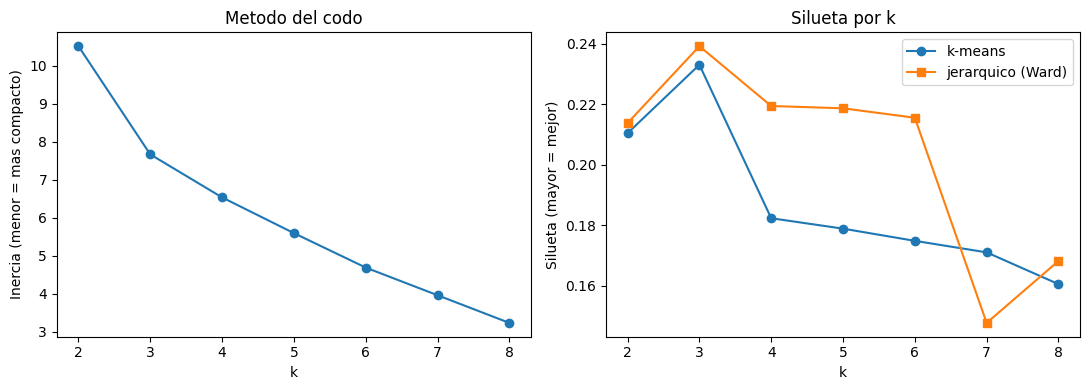

In [3]:
ks = range(2, 9)
inercias, sil_km, sil_hc = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    hc = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X)
    inercias.append(km.inertia_)
    sil_km.append(silhouette_score(X, km.labels_))
    sil_hc.append(silhouette_score(X, hc.labels_))

res = pd.DataFrame({'k': list(ks), 'inercia': np.round(inercias, 2),
                    'silueta_kmeans': np.round(sil_km, 3),
                    'silueta_ward': np.round(sil_hc, 3)})
print(res.to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(list(ks), inercias, 'o-', color='#1f77b4')
ax[0].set_xlabel('k'); ax[0].set_ylabel('Inercia (menor = mas compacto)')
ax[0].set_title('Metodo del codo')
ax[1].plot(list(ks), sil_km, 'o-', label='k-means', color='#1f77b4')
ax[1].plot(list(ks), sil_hc, 's-', label='jerarquico (Ward)', color='#ff7f0e')
ax[1].set_xlabel('k'); ax[1].set_ylabel('Silueta (mayor = mejor)')
ax[1].set_title('Silueta por k'); ax[1].legend()
plt.tight_layout(); plt.show()

**Lectura honesta:** el codo es gradual (no hay un salto claro) y la silueta máxima es ~0,23-0,24, una **separación modesta**: los distritos no forman grupos muy compactos y alejados. Dentro de esa modestia, k = 3 es donde la silueta es máxima para los dos métodos, así que **k = 3 es el candidato provisional** para este baseline, no un número de grupos validado. k = 4 (que separaría Centro-Arganzuela-Tetuán del resto del cinturón) queda como alternativa a discutir.

Tener 21 filas no impide obtener una silueta alta. Aquí el valor absoluto sí advierte de solapamiento; la comparación entre k ayuda a elegir un candidato, pero no demuestra que existan grupos naturales.

## 3. Baseline: k-means con k = 3

In [4]:
k_final = 3
km = KMeans(n_clusters=k_final, n_init=50, random_state=42).fit(X)
df['cluster'] = km.labels_

# nombres de trabajo segun el perfil que sale abajo (provisionales)
nombres = {0: 'Acomodado y envejecido', 1: 'Denso y vulnerable', 2: 'Periferico y disperso'}
df['cluster_nombre'] = df['cluster'].map(nombres)

for c in range(k_final):
    d = df[df.cluster == c]
    print(f"Cluster {c} - {nombres[c]} ({len(d)} distritos):")
    print('  ' + ', '.join(d['distrito'].str.title()))
    print()

Cluster 0 - Acomodado y envejecido (5 distritos):
  Retiro, Salamanca, Chamartin, Chamberi, Moratalaz

Cluster 1 - Denso y vulnerable (10 distritos):
  Centro, Arganzuela, Tetuan, Latina, Carabanchel, Usera, Puente De Vallecas, Ciudad Lineal, Villaverde, San Blas-Canillejas

Cluster 2 - Periferico y disperso (6 distritos):
  Fuencarral-El Pardo, Moncloa-Aravaca, Hortaleza, Villa De Vallecas, Vicalvaro, Barajas



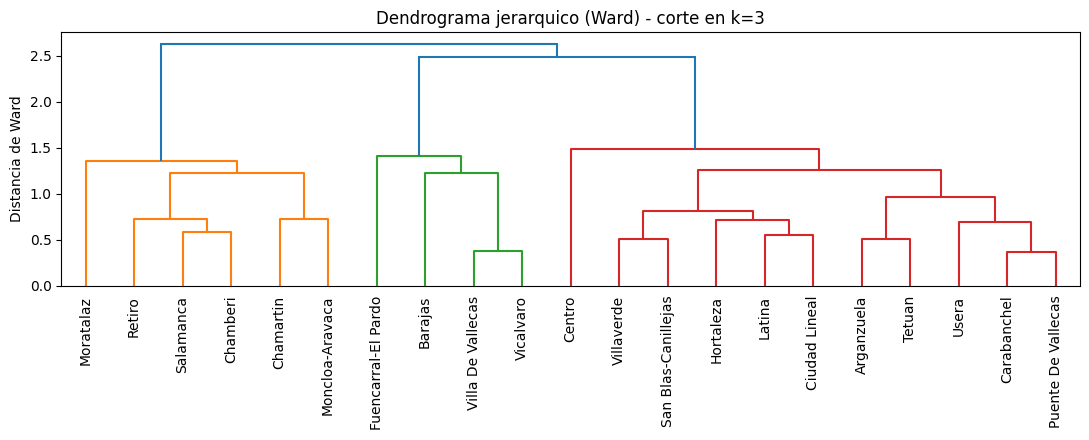

In [5]:
# dendrograma Ward: otra forma de ver la misma estructura
Z = linkage(X, method='ward')
plt.figure(figsize=(11, 4.5))
dendrogram(Z, labels=df['distrito'].str.title().tolist(), leaf_rotation=90,
           color_threshold=Z[-(k_final-1), 2])
plt.title('Dendrograma jerarquico (Ward) - corte en k=3')
plt.ylabel('Distancia de Ward')
plt.margins(y=0.08)
plt.tight_layout(); plt.show()

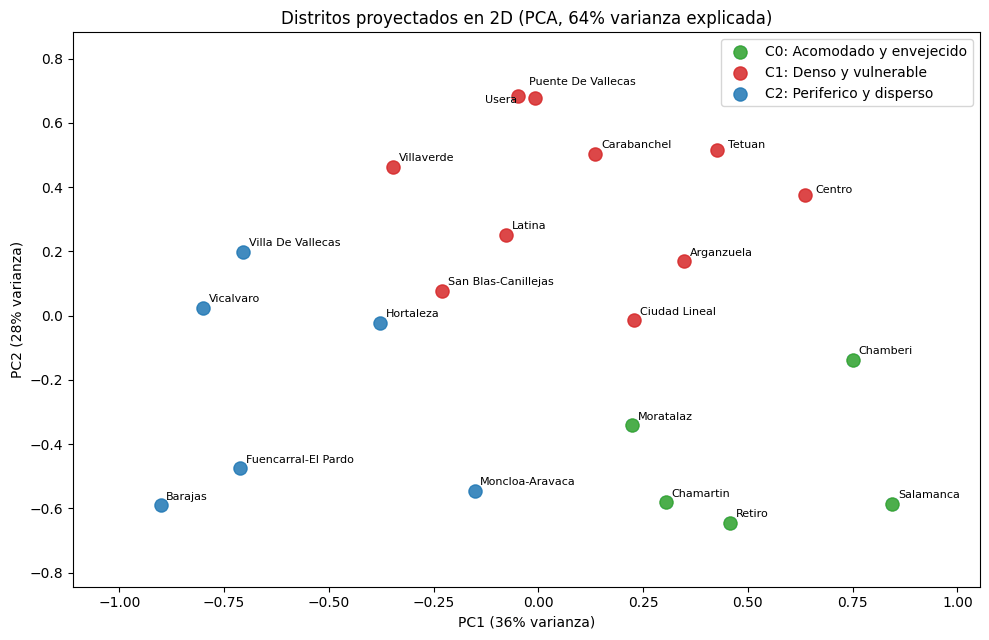

In [6]:
# vista 2D (PCA) coloreada por grupo: PCA solo para dibujar, no para decidir
pca = PCA(n_components=2, random_state=42)
P = pca.fit_transform(X)
fig, ax = plt.subplots(figsize=(10, 6.5))
colores = ['#2ca02c', '#d62728', '#1f77b4']
for c in range(k_final):
    m = df.cluster.to_numpy() == c
    ax.scatter(P[m, 0], P[m, 1], s=90, color=colores[c], label=f'C{c}: {nombres[c]}', alpha=0.85)
offsets = {'PUENTE DE VALLECAS': (8, 8), 'USERA': (-36, -4), 'CENTRO': (8, 2), 'TETUAN': (8, 2)}
for i, d in enumerate(df['distrito']):
    ax.annotate(d.title(), (P[i, 0], P[i, 1]), fontsize=8,
                xytext=offsets.get(d, (4, 4)), textcoords='offset points')
var_exp = pca.explained_variance_ratio_.sum() * 100
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% varianza)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% varianza)')
ax.set_title(f'Distritos proyectados en 2D (PCA, {var_exp:.0f}% varianza explicada)')
ax.margins(x=0.12, y=0.15)  # margen para que las etiquetas no queden recortadas
ax.legend()
plt.tight_layout(); plt.show()

## 4. Robustez del baseline (lo que aguanta y lo que no)

Antes de enseñar los perfiles, tres comprobaciones sobre la partición k = 3:

- **Sin Centro** (distrito atípico: su tasa de activaciones por 1.000 hab es casi el triple que la del segundo, ya vimos en el EDA que puede recoger demanda de visitantes y ocio nocturno, hipótesis que estos datos no permiten confirmar).
- **Sin los 4 distritos con valores imputados** en las variables usadas: la limpieza socioeconómica rellenó 10 huecos con la media de los 3 distritos más parecidos (kNN, k=3), una suposición nuestra pendiente de confirmación. De las variables del clustering, tocan la renta de Retiro y Ciudad Lineal, el % de mayores de 65 de Chamartín y Ciudad Lineal, y los centros de salud de San Blas-Canillejas.
- **Otras 19 semillas** para k-means (misma k y mismos datos).

In [7]:
from sklearn.metrics import adjusted_rand_score

# A) sin Centro
mA = df.distrito != 'CENTRO'
kmA = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X[mA.to_numpy()])
ariA = adjusted_rand_score(df.loc[mA, 'cluster'], kmA.labels_)

# B) sin los 4 distritos con celdas imputadas en las variables usadas
afectados = ['RETIRO', 'CIUDAD LINEAL', 'CHAMARTIN', 'SAN BLAS-CANILLEJAS']
mB = ~df.distrito.isin(afectados)
kmB = KMeans(n_clusters=3, n_init=50, random_state=42).fit(X[mB.to_numpy()])
ariB = adjusted_rand_score(df.loc[mB, 'cluster'], kmB.labels_)

# C) 19 semillas distintas
aris_seed = [adjusted_rand_score(df['cluster'],
             KMeans(n_clusters=3, n_init=50, random_state=s).fit(X).labels_)
             for s in range(1, 20)]

print(f"A) Sin Centro:                        ARI = {ariA:.2f} con el baseline")
print(f"B) Sin distritos con imputaciones:    ARI = {ariB:.2f} con el baseline")
print(f"C) 19 semillas distintas:             ARI min = {min(aris_seed):.2f}, mediana = {np.median(aris_seed):.2f}")

# D) sensibilidad a retirar los dos ejes completos: no es una prueba solo de imputacion.
variables_sin_ejes = [v for v in variables if v not in ['renta_media_hogar', 'pct_mayores_65']]
km_sin_ejes = KMeans(n_clusters=3, n_init=50, random_state=42).fit(nrm[variables_sin_ejes])
ari_sin_ejes = adjusted_rand_score(df['cluster'], km_sin_ejes.labels_)
print(f'D) Sin renta y porcentaje de mayores: ARI = {ari_sin_ejes:.2f}')

A) Sin Centro:                        ARI = 1.00 con el baseline
B) Sin distritos con imputaciones:    ARI = 1.00 con el baseline
C) 19 semillas distintas:             ARI min = 1.00, mediana = 1.00
D) Sin renta y porcentaje de mayores: ARI = 0.57


**Resultado:** en las tres comprobaciones la partición se mantiene igual salvo reordenación de etiquetas (ARI = 1,00). Es decir, **en estas pruebas concretas, al mantener el escalado original y k = 3, no cambian las asignaciones de los distritos comparables**. No demuestra independencia general de los datos imputados ni estabilidad ante cualquier cambio de muestra.

Lo que sí hay que decir con honestidad:

- La separación sigue siendo **modesta** (silueta global próxima a 0,23 en el baseline). Estos grupos son una forma razonable de resumir los distritos, no fronteras duras.
- Si quitamos del clustering los ejes económico y de edad enteros (renta y % de mayores de 65), la partición cambia bastante (ARI ≈ 0,57). Es esperable: esos ejes son gran parte del contenido del caso. Pero significa que el resultado **depende de variables que llevan 5 celdas imputadas pendientes de confirmar**; si Bluetab corrige esos valores, hay que rehacer el modelo.
- **La tabla mezcla todos los tipos de emergencia** sin distinguir: el 6,55 % de las activaciones no tienen correspondencia con el catálogo de tipos limpio (quedan con su etiqueta original) y las 39 filas de `VALLECAS` siguen como NO CONSTA. No hay segmentación por tipo de emergencia todavía.
- La población de Barajas es una estimación (densidad x superficie), no un dato real, y de ella depende su tasa de activaciones por habitante.

## 5. Perfil provisional de cada grupo (valores reales, no normalizados)

In [8]:
cols_desc = ['renta_media_hogar', 'tasa_paro', 'indice_vulnerabilidad', 'pct_mayores_65',
             'pct_extranjeros', 'densidad_hab_km2', 'activaciones_por_1000hab',
             'pct_prioridad_alta', 'edad_media_paciente', 'tiempo_respuesta_medio_min']
perfil = df.groupby('cluster_nombre')[cols_desc].mean().round(2)
perfil.loc['MEDIA DE LOS 21 DISTRITOS'] = df[cols_desc].mean().round(2)
print(perfil.T.to_string())

cluster_nombre              Acomodado y envejecido  Denso y vulnerable  Periferico y disperso  MEDIA DE LOS 21 DISTRITOS
renta_media_hogar                         56418.60            33037.20               43906.83                   41709.81
tasa_paro                                     7.10               12.64                   9.92                      10.54
indice_vulnerabilidad                         0.26                0.59                   0.42                       0.46
pct_mayores_65                               24.72               18.14                  15.50                      18.95
pct_extranjeros                              11.72               20.22                  14.45                      16.55
densidad_hab_km2                          21956.68            17689.91                2654.98                   14410.11
activaciones_por_1000hab                     45.46               52.13                  39.89                      47.04
pct_prioridad_alta              

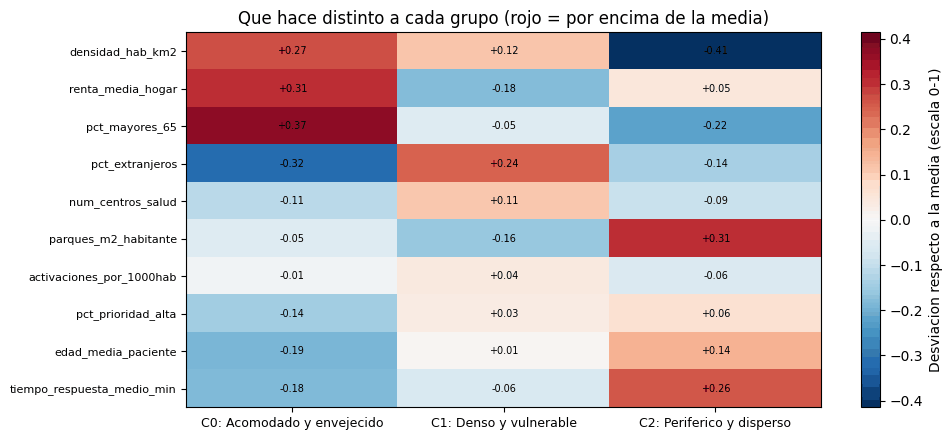

In [9]:
# que variables hacen distinto a cada grupo (media normalizada vs media global)
med_global = nrm[variables].mean()
medias = nrm[variables].assign(cluster=df.cluster).groupby('cluster').mean()
dif = (medias - med_global)

plt.figure(figsize=(10, 4.5))
im = plt.imshow(dif.T, cmap='RdBu_r', vmin=-np.abs(dif.to_numpy()).max(), vmax=np.abs(dif.to_numpy()).max(), aspect='auto')
plt.colorbar(im, label='Desviacion respecto a la media (escala 0-1)')
plt.yticks(range(len(variables)), variables, fontsize=8)
plt.xticks(range(k_final), [f'C{c}: {nombres[c]}' for c in range(k_final)], fontsize=9)
for i in range(len(variables)):
    for c in range(k_final):
        plt.text(c, i, f'{dif.T.iloc[i, c]:+.2f}', ha='center', va='center', fontsize=7)
plt.title('Que hace distinto a cada grupo (rojo = por encima de la media)')
plt.tight_layout(); plt.show()

**Lectura provisional de los tres grupos** (pendiente de la validación del grupo y de Bluetab):

- **C0 - Acomodado y envejecido** (Retiro, Salamanca, Chamartín, Chamberí, Moratalaz): renta muy por encima de la media (56.400 € frente a 41.700 €), paro bajo (7,1 %), el más envejecido (24,7 % de mayores de 65) y los mejores tiempos medios de respuesta (7,6 min).
- **C1 - Denso y vulnerable** (Centro, Arganzuela, Tetuán, Latina, Carabanchel, Usera, Puente de Vallecas, Ciudad Lineal, Villaverde, San Blas-Canillejas): renta baja (33.000 €), paro alto (12,6 %), más población extranjera (20,2 %) y donde se concentra la mayor parte de las activaciones registradas.
- **C2 - Periférico y disperso** (Fuencarral-El Pardo, Moncloa-Aravaca, Hortaleza, Villa de Vallecas, Vicálvaro, Barajas): densidad muy baja (2.650 hab/km² frente a 14.400 de media) y los peores tiempos medios de respuesta (9,9 min frente a 8,6 de media distrital; Barajas 12,0, Villa de Vallecas 10,2 y Vicálvaro 10,1 son los tres distritos con peor media). **No sabemos por qué**: podría deberse a distancias, cobertura, tráfico u otras causas; con estos datos no se puede distinguir, así que queda como observación descriptiva, no como explicación.

Ojo con Centro: su tasa de activaciones por 1.000 hab (147,9) es casi el triple que la del segundo distrito, y podría recoger demanda de visitantes y ocio nocturno; no podemos separar residentes y visitantes con estas tablas. Forma parte del C1, pero es un distrito atípico dentro de él (de ahí la comprobación A de la sección 4).

## 6. Oferta y demanda por grupo: solo descripción, sin conclusiones de cobertura

Datos descriptivos por grupo. **No se puede deducir si la oferta es suficiente o dónde falta cobertura**: las bases catalogadas por distrito no equivalen a unidades disponibles ni a áreas de servicio (una base atiende más allá de su distrito y no sabemos el reparto real), y además faltan por confirmar unidades, hospitales y camas de 3 distritos (Puente de Vallecas, Villa de Vallecas y camas de Arganzuela). Por eso aquí no calculamos ratios de carga por base: con lo que sabemos, serían engañosos.

                        distritos  activaciones  poblacion  bases_samur_catalogadas  pct_activaciones  activaciones_por_1000hab  media_distrital_respuesta_min
cluster_nombre                                                                                                                                                
Acomodado y envejecido          5         30241     647506                        1              20.0                      46.7                           7.60
Denso y vulnerable             10         92262    1866858                        9              61.1                      49.4                           8.24
Periferico y disperso           6         28527     795324                        5              18.9                      35.9                           9.94


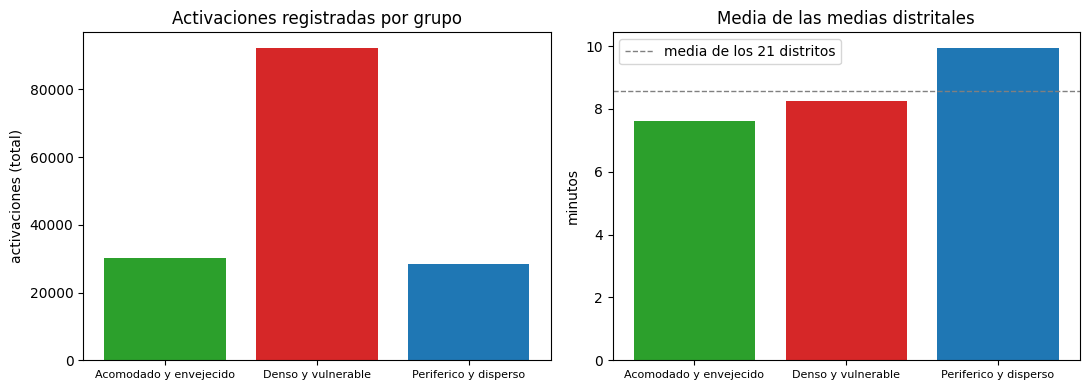

Distritos con recursos aun desconocidos (pendientes de Bluetab):
          distrito        cluster_nombre
        ARGANZUELA    Denso y vulnerable
PUENTE DE VALLECAS    Denso y vulnerable
 VILLA DE VALLECAS Periferico y disperso


In [10]:
desc = df.groupby('cluster_nombre').agg(
    distritos=('distrito', 'count'),
    activaciones=('n_activaciones', 'sum'),
    poblacion=('poblacion', 'sum'),
    bases_samur_catalogadas=('num_bases_samur', 'sum'))
desc['pct_activaciones'] = (desc['activaciones'] / desc['activaciones'].sum() * 100).round(1)
desc['activaciones_por_1000hab'] = (desc['activaciones'] / desc['poblacion'] * 1000).round(1)
desc['media_distrital_respuesta_min'] = df.groupby('cluster_nombre')['tiempo_respuesta_medio_min'].mean().round(2)
print(desc.to_string())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
colores_ord = ['#2ca02c', '#d62728', '#1f77b4']
ax[0].bar(desc.index, desc['activaciones'], color=colores_ord)
ax[0].set_title('Activaciones registradas por grupo'); ax[0].set_ylabel('activaciones (total)')
ax[0].tick_params(axis='x', labelsize=8)
ax[1].bar(desc.index, desc['media_distrital_respuesta_min'], color=colores_ord)
ax[1].axhline(df['tiempo_respuesta_medio_min'].mean(), color='grey', ls='--', lw=1, label='media de los 21 distritos')
ax[1].set_title('Media de las medias distritales'); ax[1].set_ylabel('minutos'); ax[1].legend()
ax[1].tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.show()

print('Distritos con recursos aun desconocidos (pendientes de Bluetab):')
desconocidos = df[df[['unidades_samur', 'num_hospitales_cat', 'camas_hospital']].isna().any(axis=1)]
print(desconocidos[['distrito', 'cluster_nombre']].to_string(index=False))

Lo único que se puede decir:

- El **C1** concentra la mayoría de las activaciones registradas (~92.300, el 61 %) y tiene la tasa por habitante más alta (49,4 por 1.000 hab, inflada por Centro).
- El **C2** tiene la tasa por habitante más baja (35,9) y, como se ha dicho, los peores tiempos medios de respuesta, sin que sepamos la causa.
- El **C0** tiene 1 base catalogada para sus 5 distritos. No se puede interpretar como falta de cobertura: no sabemos las unidades reales, sus áreas de servicio ni cómo cubren los distritos vecinos.

## 8. Limitaciones y siguientes pasos

**Limitaciones (resumen de lo ya dicho):**

- Baseline exploratorio con separación modesta (silueta ~0,23); k = 3 es candidato provisional, no validado.
- La estructura aguanta quitar Centro, quitar los distritos imputados y cambiar la semilla, pero depende de los ejes económico y de edad, que llevan 5 celdas imputadas pendientes de confirmación.
- La tabla mezcla todos los tipos de emergencia (6,55 % sin correspondencia de catálogo); no hay segmentación por tipo.
- La oferta está incompleta (VALLECAS ambiguo, camas sin dato) y las bases catalogadas no miden cobertura real: no hay ninguna conclusión operacional.
- Es un modelo descriptivo, no predictivo: no dice qué pasará, solo cómo se parecen los distritos hoy. No se ha medido ningún ahorro.

**Siguientes pasos propuestos:**

1. Resolver con Bluetab los recursos desconocidos y confirmar las 10 imputaciones; rehacer el modelo si cambian.
2. Valorar k = 4 como alternativa (separa Centro-Arganzuela-Tetuán).
3. No se añade DBSCAN a este avance: con solo 21 distritos habría que justificar especialmente sus parámetros de densidad y la interpretación del ruido. No es una prohibición por tamaño, sino una decisión de alcance: primero entender y contrastar el baseline actual.
4. Si el grupo valida los perfiles en la reunión, llevarlos al mapa de distritos del EDA y a las diapositivas/memoria.

## 9. Reproducibilidad

La respuesta por grupo se calcula dando el mismo peso a cada distrito. **No es la media de todas sus activaciones**: para obtenerla harían falta los conteos de respuestas válidas por distrito, porque hay tiempos desconocidos. No se ajusta por gravedad, distancia o tráfico.

## 7. Diagnóstico por distrito: dónde se solapan los grupos

La silueta global puede ocultar asignaciones dudosas. Se calcula la silueta individual con la misma distancia euclídea que usa el clustering: cerca de 1 indica mayor separación, cerca de 0 indica frontera y por debajo de 0 indica que el distrito está, en promedio, más cerca de otro grupo. No es una probabilidad ni una medida de confianza estadística.

Se muestra además el Ward de k = 3 tras alinear sus etiquetas con k-means. Esa coincidencia compara dos algoritmos sobre los mismos datos: no es validación externa. No se descarta ningún distrito por tener silueta baja.

 distrito_id            distrito  cluster         cluster_nombre  silueta  cluster_ward_alineado  coincide_ward
           9     MONCLOA-ARAVACA        2  Periferico y disperso   -0.038                      0          False
          16           HORTALEZA        2  Periferico y disperso   -0.010                      1          False
          18   VILLA DE VALLECAS        2  Periferico y disperso    0.092                      2           True
          15       CIUDAD LINEAL        1     Denso y vulnerable    0.108                      1           True
          20 SAN BLAS-CANILLEJAS        1     Denso y vulnerable    0.123                      1           True
          14           MORATALAZ        0 Acomodado y envejecido    0.132                      0           True
           1              CENTRO        1     Denso y vulnerable    0.149                      1           True
           7            CHAMBERI        0 Acomodado y envejecido    0.172                      0        

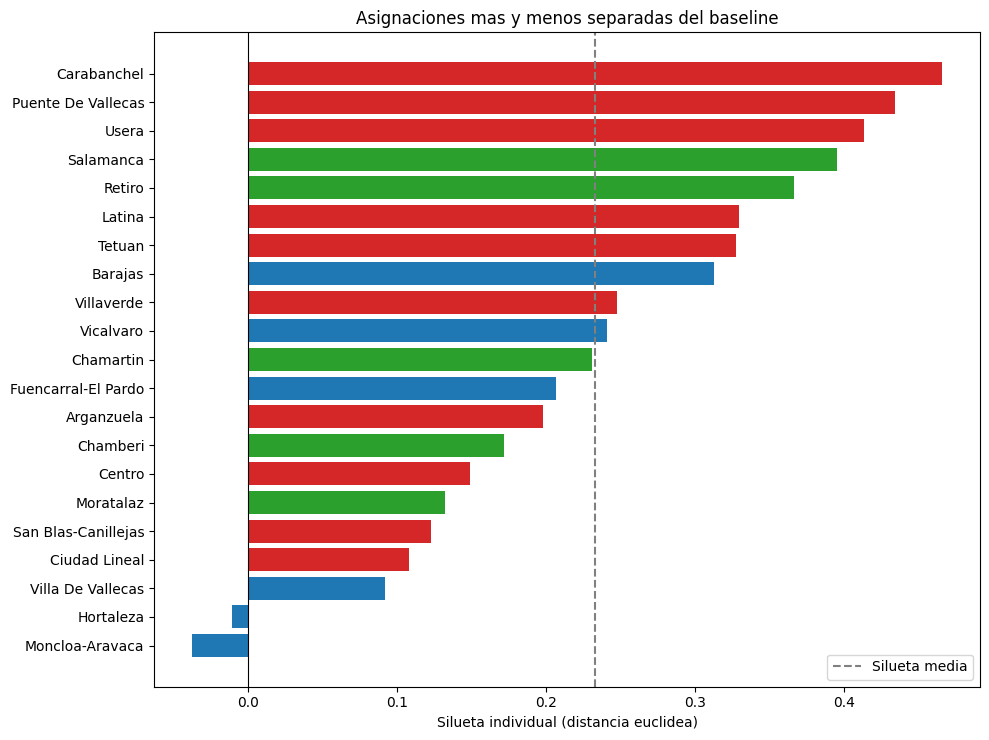

Menor separacion: Moncloa-Aravaca, Hortaleza, Villa De Vallecas
Leer estos casos junto con sus valores reales; no son errores automaticos.


In [11]:
from sklearn.metrics import silhouette_samples
from scipy.optimize import linear_sum_assignment

sil_individual = silhouette_samples(X, km.labels_)
ward = AgglomerativeClustering(n_clusters=k_final, linkage='ward').fit_predict(X)
contingencia = pd.crosstab(km.labels_, ward).reindex(index=range(k_final), columns=range(k_final), fill_value=0)
fila, columna = linear_sum_assignment(-contingencia.to_numpy())
equivalencias = dict(zip(columna, fila))
ward_alineado = np.array([equivalencias[c] for c in ward])

diagnostico = df[['distrito_id', 'distrito', 'cluster', 'cluster_nombre']].copy()
diagnostico['silueta'] = sil_individual
diagnostico['cluster_ward_alineado'] = ward_alineado
diagnostico['coincide_ward'] = km.labels_ == ward_alineado
print(diagnostico.sort_values('silueta').to_string(index=False, float_format=lambda x: f'{x:.3f}'))
print(f'\nSilueta global: {sil_individual.mean():.3f}')
print(f'Distritos con silueta negativa: {(sil_individual < 0).sum()} de {len(df)}')
print(f'Coincidencia KMeans-Ward: {(km.labels_ == ward_alineado).sum()} de {len(df)}')
print('ARI entre metodos:', round(adjusted_rand_score(km.labels_, ward), 3))

orden = diagnostico.sort_values('silueta')
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.barh(orden.distrito.str.title(), orden.silueta,
        color=[colores[c] for c in orden.cluster])
ax.axvline(0, color='black', lw=0.8)
ax.axvline(sil_individual.mean(), color='grey', ls='--', label='Silueta media')
ax.set_xlabel('Silueta individual (distancia euclidea)')
ax.set_title('Asignaciones mas y menos separadas del baseline')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

print('Menor separacion:', ', '.join(orden.head(3).distrito.str.title()))
print('Leer estos casos junto con sus valores reales; no son errores automaticos.')

**Lectura de esta ejecución:** Moncloa-Aravaca (-0,038) y Hortaleza (-0,010) tienen silueta negativa y cambian de grupo con Ward. Los otros 19 distritos coinciden tras alinear las etiquetas (ARI entre métodos = 0,748). Son casos para revisar, no motivos para borrar observaciones ni retocar k hasta que parezca mejor.

### Reutilizar resultados sin copiar etiquetas a mano

La siguiente celda prepara dos tablas en memoria: una fila por distrito con su asignación y diagnóstico, y los perfiles medios en valores reales. La exportación es opcional: por defecto **no crea archivos ni cambia las entradas**. Para reutilizarlos en un mapa o en la memoria, cambia `exportar` a `True`; se guardarán en `resultados_clustering/` dentro de la carpeta del caso. Las etiquetas de grupo solo sirven para esta ejecución y no deben interpretarse como un orden de gravedad.

In [12]:
asignaciones = df.merge(
    diagnostico[['distrito_id', 'silueta', 'cluster_ward_alineado', 'coincide_ward']],
    on='distrito_id', how='left', validate='one_to_one')
perfiles = df.groupby(['cluster', 'cluster_nombre'])[cols_desc].mean().reset_index()
assert len(asignaciones) == 21 and asignaciones['silueta'].notna().all()
exportar = False
if exportar:
    salida = carpeta / 'resultados_clustering'
    salida.mkdir(exist_ok=True)
    asignaciones.to_csv(salida / 'distritos_con_cluster.csv', index=False)
    perfiles.to_csv(salida / 'perfiles_cluster.csv', index=False)
    print('Resultados descriptivos guardados en', salida)
else:
    print('Tablas asignaciones y perfiles listas en memoria. No se han creado CSV nuevos.')

Tablas asignaciones y perfiles listas en memoria. No se han creado CSV nuevos.


In [13]:
import sys, sklearn, scipy, matplotlib
print('python', sys.version.split()[0])
print('pandas', pd.__version__)
print('numpy', np.__version__)
print('scikit-learn', sklearn.__version__)
print('scipy', scipy.__version__)
print('matplotlib', matplotlib.__version__)
print('\nk-means: n_init=50, random_state=42 en el baseline y las comparaciones de k; las pruebas de semillas cambian random_state')

python 3.10.12
pandas 2.3.3
numpy 2.2.6
scikit-learn 1.7.2
scipy 1.15.3
matplotlib 3.10.9

k-means: n_init=50, random_state=42 en el baseline y las comparaciones de k; las pruebas de semillas cambian random_state
